# Manejo de datos y esquemas de clasificación


- Clasificación binaria.
    - Regresión logística y función sigmoidea
    - Support Vector Machines
    - Métricas


In [11]:
# Imports necesarios
import numpy as np
import pandas as pd

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, log_loss, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

import matplotlib.pyplot as plt
import seaborn as sns
# from scipy import stats

## Clasificación Binaria: Modelos

In [12]:
# Cargar el dataset de desersión de estudiantes
data = pd.read_csv('../data/dataset_TP1_2026.csv')
data.head()

,Estudios_máximos_antes_de_la_inscripción,estado_civil,modo_aplicacion,sexo,desplazado,target,Carrera,Asistencia_diurna/nocturna,Cualificación_promedio_de_estudios_previos,Puntaje_en_examen_de_ingreso,...,Unidades_curriculares_1er_semestre_(aprobadas),Nota_promedio_en_el_1er_semestre,Unidades_curriculares_2do_semestre_(inscrito),Cantidad_de_evaluaciones_en_el_2do_semestre_,Unidades_curriculares_2do_semestre_(aprobadas),Nota_promedio_en_el_2do_semestre,Demanda_Cog_Padre,Demanda_Cog_Madre,Ingresos_Padre,Ingresos_Madre
0,Educación Secundaria,Soltero,Acceso General,Femenino,Sí,Graduado,Turismo,Diurna,65,61,...,6,63,6,8,5,69,Muy baja demanda cognitiva,Muy baja demanda cognitiva,Bajos ingresos,Bajos ingresos
1,Educación Secundaria,Soltero,Acceso por Normativa Específica,Femenino,No,Desertor,Enfermería,Diurna,67,58,...,0,0,7,7,0,0,Muy baja demanda cognitiva,Muy baja demanda cognitiva,Bajos ingresos,Bajos ingresos
2,Educación Secundaria,Soltero,Acceso General,Femenino,Sí,En Curso,Gestión,Diurna,64,62,...,3,53,5,10,2,52,Muy baja demanda cognitiva,Demanda cognitiva media,Bajos ingresos,Ingresos medios
3,Educación Secundaria,Soltero,Acceso General,Femenino,Sí,En Curso,Enfermería,Diurna,67,54,...,5,63,7,8,3,58,Demanda cognitiva media,Demanda cognitiva media,Ingresos medios,Ingresos medios
4,Educación Secundaria,Soltero,Acceso General,Femenino,Sí,En Curso,Publicidad y Marketing,Diurna,68,62,...,6,62,6,9,6,65,Muy alta demanda cognitiva,Muy baja demanda cognitiva,Altos ingresos,Bajos ingresos


## Valores NA
No se observan valores nulos

In [13]:
data.isna().sum()

Estudios_máximos_antes_de_la_inscripción          0
estado_civil                                      0
modo_aplicacion                                   0
sexo                                              0
desplazado                                        0
target                                            0
Carrera                                           0
Asistencia_diurna/nocturna                        0
Cualificación_promedio_de_estudios_previos        0
Puntaje_en_examen_de_ingreso                      0
Necesidades_educativas_especiales                 0
Tiene_deuda                                       0
Pago_de_matrícula_al_día                          0
Poseedor_de_Beca                                  0
Edad_al_momento_de_la_inscripción                 0
Estudiante_Internacional                          0
Unidades_curriculares_1er_semestre_(inscrito)     0
Cantidad_de_evaluaciones_en_el_1er_semestre       0
Unidades_curriculares_1er_semestre_(aprobadas)    0
Nota_promedi

Distribución del target

In [14]:
data["target"] = np.where(data['target'] == "Desertor", 1, 0)   # Seleccionar filas donde 'target' es 1
data['target'].value_counts(normalize=True)  # Calcular la proporción de cada clase

target
0    0.66942
1    0.33058
Name: proportion, dtype: float64

## OneHotEncoding

In [15]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 28 columns):
 #   Column                                          Non-Null Count  Dtype
---  ------                                          --------------  -----
 0   Estudios_máximos_antes_de_la_inscripción        50000 non-null  str  
 1   estado_civil                                    50000 non-null  str  
 2   modo_aplicacion                                 50000 non-null  str  
 3   sexo                                            50000 non-null  str  
 4   desplazado                                      50000 non-null  str  
 5   target                                          50000 non-null  int64
 6   Carrera                                         50000 non-null  str  
 7   Asistencia_diurna/nocturna                      50000 non-null  str  
 8   Cualificación_promedio_de_estudios_previos      50000 non-null  int64
 9   Puntaje_en_examen_de_ingreso                    50000 non-null  int64
 1

In [16]:
columnas_categoricas = data.select_dtypes(
    include=["object", "category"]
).columns
X = pd.get_dummies(data.drop("target", axis=1), columns=columnas_categoricas, drop_first=True)

C:\Users\mbustos_lightech\AppData\Local\Temp\ipykernel_8928\1863039316.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = data.select_dtypes(


In [17]:
print("\n" + "=" * 50)
print("Dimensiones del dataset original:", data.shape)
print("Shape of the transformed feature matrix X:", X.shape)
print("=" * 50)
print("\n" + "=" * 50)
print("Columnas categóricas:", columnas_categoricas)
print("=" * 50)


Dimensiones del dataset original: (50000, 28)
Shape of the transformed feature matrix X: (50000, 61)

Columnas categóricas: Index(['Estudios_máximos_antes_de_la_inscripción', 'estado_civil',
       'modo_aplicacion', 'sexo', 'desplazado', 'Carrera',
       'Asistencia_diurna/nocturna', 'Necesidades_educativas_especiales',
       'Tiene_deuda', 'Pago_de_matrícula_al_día', 'Poseedor_de_Beca',
       'Estudiante_Internacional', 'Demanda_Cog_Padre', 'Demanda_Cog_Madre',
       'Ingresos_Padre', 'Ingresos_Madre'],
      dtype='str')


## Split 80/20

In [18]:
y = data['target']  # Variable objetivo

# dividir los datos en conjunto de entrenamiento y prueba 80/20 estratificado
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)


In [19]:
print("\n"+ "=" * 50)
print("Proporción de clases en el conjunto de entrenamiento:")
print(y_train.value_counts(normalize=True))
print("=" * 50)
print("\n" + "=" * 50)
print("Proporción de clases en el conjunto de validación:")
print(y_test.value_counts(normalize=True))
print("=" * 50)


Proporción de clases en el conjunto de entrenamiento:
target
0    0.669425
1    0.330575
Name: proportion, dtype: float64

Proporción de clases en el conjunto de validación:
target
0    0.6694
1    0.3306
Name: proportion, dtype: float64


---
## Regresión logística

La [regresión logística](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression) es una técnica de aprendizaje supervisado utilizada para predecir la probabilidad de una variable categórica binaria en función de una o más variables predictoras. En scikit-learn, se puede utilizar la clase `LogisticRegression` para construir modelos de regresión logística.

La RL puede verse como un modelo lineal generalizado, en el que a una combinación lineal de atributos o transformaciones se le aplica una función no lineal (función de activación), que en este caso particular es la **función sigmoidea** o función logítica. La función sigmoidea se utiliza para transformar la variable dependiente en un rango entre 0 y 1, y se define como:

$ \sigma (z) = \frac{1}{1+e^{-z}} $

![](https://upload.wikimedia.org/wikipedia/commons/thumb/8/88/Logistic-curve.svg/600px-Logistic-curve.svg.png)

donde $z$ es la entrada que en la regresion logística es en realidad una combinación lineal:

$z = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_px_p$

quedando el modelo $f$ para un dato $x$:

\begin{equation}
f(x) = \sigma(\beta_0 + \sum_{j=1}^p \beta_j x_j) = \frac{1}{1+e^{-(\beta_0 + \sum_{j=1}^p \beta_j x_j)}}
\end{equation}

En el caso de clasificación binaria se interpreta como la probabilidad de la etiqueta correspondiente a los features $x$ de pertenecer a la clase de interés o clase positiva (por ej: si un tipo de cancer es maligno) o de pertenecer a la clase negativa ($\mathcal{C}_P$ o $\mathcal{C}_N$). Volvemos a usar $y$ para la clase de $x$ y la predicción del modelo será $\hat{y}$:

$$
\hat{y} = \max \{ P(y\in \mathcal{C}_P|x), P(y\in \mathcal{C}_N|x) \}
$$

Pero esto se puede reescribir como:

$$
\hat{y} = \max \{ P(y\in \mathcal{C}_P|x), 1 - P(y\in \mathcal{C}_P|x) \}
$$

Nuestro modelo $f$ justamente predecirá esto:$f(x) = P(y\in \mathcal{C}_P|x)$, quedando

$$
\hat{y}=  \max \{ f(x), 1 - f(x) \}
$$

por lo tanto si la predicción es mayor a $0.5$ se predice clase positiva y sino clase negativa.

In [20]:
# Instanciamos el modelo
print('Ajustando una regresión logística...')

# crear el modelo de regresión logística
reg_log = LogisticRegression(penalty=None, max_iter=10000)

# entrenar el modelo con los datos de entrenamiento
reg_log.fit(X_train, y_train)

# hacer predicciones con los datos de prueba
y_pred = reg_log.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)


precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
F1 = 2 * (precision * recall) / (precision + recall)

print("\n" + "=" * 50)
print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("F1-Score: {:.2f}%".format(F1 * 100))
print("=" * 50)

Ajustando una regresión logística...


c:\Users\mbustos_lightech\Documents\Master\Aprendizaje_automatico\TP1\alumnos_desertores\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



Accuracy de la clasificación: 90.68%
Precision: 89.78%
Recall: 81.03%
F1-Score: 85.18%


### Matriz de confusion en el caso binario

Estuvimos viendo como calcular la performance de nuestro modelo a mano, pero scikit-learn nos provee ya un [módulo](https://scikit-learn.org/stable/api/sklearn.metrics.html#classification-metrics) completo con implementación de muchas métricas para clasificación (y muchos otros problemas). Veamos como calcular algunas como la matriz de confusión o el `f1-score`.

Confusion matrix:


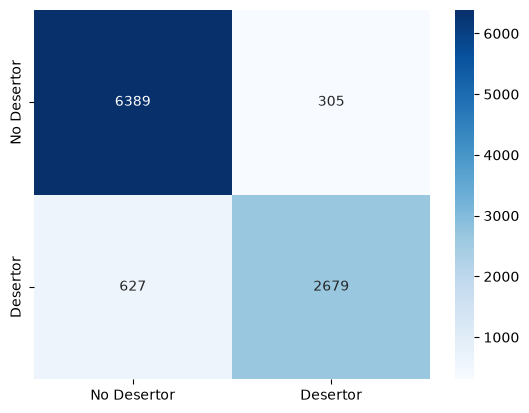

In [21]:
C = confusion_matrix(y_test, y_pred)
print('Confusion matrix:')
s = sns.heatmap(C, annot=True, fmt='d', cmap='Blues', xticklabels=['No Desertor', 'Desertor'], yticklabels=['No Desertor', 'Desertor'])
plt.show()

### Curva ROC

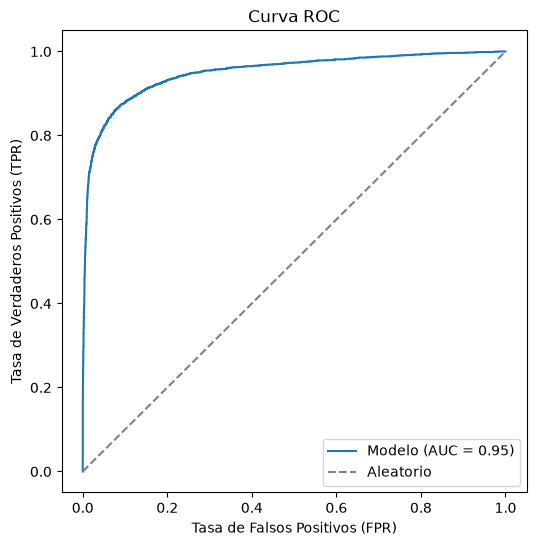

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score

# Obtener probabilidades de predicción
y_probs = reg_log.predict_proba(X_test)[:, 1]  # probabilidad clase positiva

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_probs)

# Calcular AUC
auc = roc_auc_score(y_test, y_probs)

# 7. Graficar
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"Modelo (AUC = {auc:.2f})")
plt.plot([0,1], [0,1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC")
plt.legend()
plt.show()

### Clasifiaction Report

In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93      6694
           1       0.90      0.81      0.85      3306

    accuracy                           0.91     10000
   macro avg       0.90      0.88      0.89     10000
weighted avg       0.91      0.91      0.91     10000



### Optimización de HP con GridsearchCV
 hiperparámetro para cada modelo: regresión logística, SVM y KNN. Para cada modelo definir una grilla para ese hiperparámetro (no tienen porque ser muchos). Elija el mejor valor de dicho hiperparámetro utilizando Cross Validation en el conjunto de entrenamiento para f1-score. Una vez elegido ese mejor modelo, reentrene el modelo en todo el conjunto de entrenamiento. Hint1: Puede ser de utilidad utilizar la función GridSearchCV.

In [24]:
from sklearn.model_selection import GridSearchCV

########################################
# crear el modelo de regresión logística
########################################
reg_log = LogisticRegression()

# Versión con GridSearchCV
param_grid = {
    'max_iter': [100, 1000, 5000, 10000],
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid_search = GridSearchCV(reg_log, param_grid=param_grid, scoring="f1", cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters Regresion Logistica:", grid_search.best_params_)
print("Best Estimator Regresion Logistica:", grid_search.best_estimator_)



Best Parameters Regresion Logistica: {'C': 100, 'max_iter': 1000}
Best Estimator Regresion Logistica: LogisticRegression(C=100, max_iter=1000)


c:\Users\mbustos_lightech\Documents\Master\Aprendizaje_automatico\TP1\alumnos_desertores\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [34]:
# 6. Evaluar
y_pred = grid_search.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
F1 = 2 * (precision * recall) / (precision + recall)

print("\n" + "=" * 50)
print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("F1-Score: {:.2f}%".format(F1 * 100))
print("=" * 50)


Accuracy de la clasificación: 90.68%
Precision: 89.81%
Recall: 81.00%
F1-Score: 85.18%


---
## Support Vector Machines (SVM)

Los modelos de SVM (**Máquinas de Vectores de Soporte**) son un conjunto de algoritmos de aprendizaje supervisado utilizados para la clasificación y regresión. En clasificación, el modelo de SVM se basa en la idea de encontrar el hiperplano que mejor separa los datos de diferentes clases. Este hiperplano es definido por un conjunto de vectores de soporte, que son los puntos más cercanos a la frontera de decisión.

![](https://upload.wikimedia.org/wikipedia/commons/thumb/7/72/SVM_margin.png/300px-SVM_margin.png)

El modelo de SVM se puede representar matemáticamente de la siguiente manera:

Para el caso de clasificación binaria, el objetivo es encontrar el hiperplano que mejor separa los datos de dos clases. Dado un conjunto de entrenamiento ${(\mathbf{x}_1, y_1),...,(\mathbf{x}_m, y_m)}$, donde $\mathbf{x}_i \in \mathbb{R}^n$ es el vector de características del $i$-ésimo ejemplo y $y_i \in {-1, 1}$ es su correspondiente etiqueta de clase, el hiperplano que mejor separa los datos se puede encontrar resolviendo el siguiente problema de optimización:

$\min_{\mathbf{w}, b} \frac{1}{2}||\mathbf{w}||^2$

sujeto a $y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \geq 1$ para todo $i=1,...,m$

La función costo que se minimiza permite encontrar el hiperplano que maximiza el margen (es decir, la distancia a los puntos más cercanos de cada clase), mientras que las restricciones aseguran que dicho hiperplano separa correctamente los datos de ambas clases. Podemos usar su implementación [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) de la librería scikit-learn para implementar SVM.

In [25]:
from sklearn.svm import SVC

# crear el modelo SVM
model_super_vector_machine = SVC(kernel='linear', C=1, random_state=42, probability=True)

# entrenar el modelo con los datos de entrenamiento
model_super_vector_machine.fit(X_train, y_train)

# hacer predicciones con los datos de prueba
y_pred = model_super_vector_machine.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
F1 = 2 * (precision * recall) / (precision + recall)

print("\n" + "=" * 50)
print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("F1-Score: {:.2f}%".format(F1 * 100))
print("=" * 50)

c:\Users\mbustos_lightech\Documents\Master\Aprendizaje_automatico\TP1\alumnos_desertores\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Accuracy de la clasificación: 89.59%
Precision: 91.38%
Recall: 75.65%
F1-Score: 82.77%


### Matriz de confusion en el caso binario

Estuvimos viendo como calcular la performance de nuestro modelo a mano, pero scikit-learn nos provee ya un [módulo](https://scikit-learn.org/stable/api/sklearn.metrics.html#classification-metrics) completo con implementación de muchas métricas para clasificación (y muchos otros problemas). Veamos como calcular algunas como la matriz de confusión o el `f1-score`.

Confusion matrix:


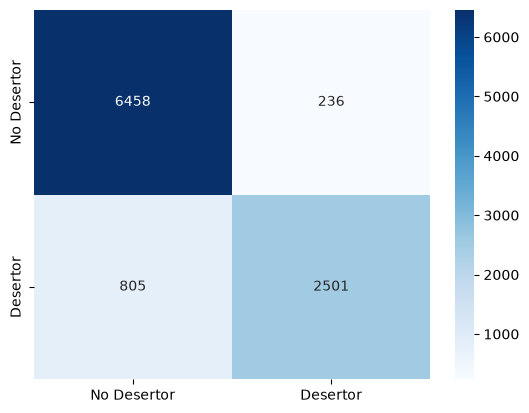

In [26]:
C = confusion_matrix(y_test, y_pred)
print('Confusion matrix:')
s = sns.heatmap(C, annot=True, fmt='d', cmap='Blues', xticklabels=['No Desertor', 'Desertor'], yticklabels=['No Desertor', 'Desertor'])
plt.show()

### Curva ROC

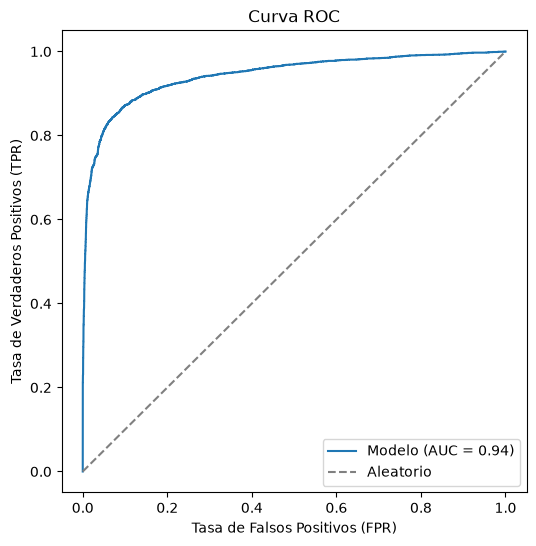

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

# Obtener probabilidades de predicción
y_score = model_super_vector_machine.decision_function(X_test)  # valores de decisión

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# Calcular AUC
auc = roc_auc_score(y_test, y_score)

# 7. Graficar
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"Modelo (AUC = {auc:.2f})")
plt.plot([0,1], [0,1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC")
plt.legend()
plt.show()

## Optimización de HP con GridsearchCV
 hiperparámetro para cada modelo: regresión logística, SVM y KNN. Para cada modelo definir una grilla para ese hiperparámetro (no tienen porque ser muchos). Elija el mejor valor de dicho hiperparámetro utilizando Cross Validation en el conjunto de entrenamiento para f1-score. Una vez elegido ese mejor modelo, reentrene el modelo en todo el conjunto de entrenamiento. Hint1: Puede ser de utilidad utilizar la función GridSearchCV.

In [28]:
# ######################
# # crear el modelo SVM
# #######################
# model_SVM = SVC(random_state=42)

# # Versión con GridSearchCV
# param_grid = {
#     "C": [0.1, 1, 10, 100],
#     "kernel": ["linear", "rbf", "poly"],
#     #"gamma": ["scale", "auto", 0.01, 0.1, 1],
#     #"degree": [2, 3, 4]   # solo aplica si kernel="poly"
# }

# # entrenar el modelo con los datos de entrenamiento
# model_SVM.fit(X_train, y_train)

# grid_search = GridSearchCV(model_SVM, param_grid=param_grid, scoring="f1", cv=5, n_jobs=-1)
# grid_search.fit(X_train, y_train)

# print("Best Parameters SVM:", grid_search.best_params_)
# print("Best Estimator SVM:", grid_search.best_estimator_)

## Arbol de decisión


In [29]:
from sklearn.tree import DecisionTreeClassifier

# Instanciar árbol de clasificación profundo para make_moons
model_tree = DecisionTreeClassifier(max_depth=10, random_state=42)

# Fit de los árboles en make_moons
model_tree.fit(X_train, y_train)

# hacer predicciones con los datos de prueba
y_pred = model_tree.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
F1 = 2 * (precision * recall) / (precision + recall)

print("\n" + "=" * 50)
print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("F1-Score: {:.2f}%".format(F1 * 100))
print("=" * 50)


Accuracy de la clasificación: 90.20%
Precision: 90.10%
Recall: 79.04%
F1-Score: 84.21%


### Optimización de Hiperparámetros - Random Search

Los árboles cuentan con muchos hiperparámetros para elegir, lo cuál los hace muy versátiles pero tienen una gran tendencia a *overfitear* los datos. Muchos de estos hiperparámetros tienen como objetivo controlar la complejidad del modelo y evitar asi el overfitting. Algunos de los más importantes implementados en scikit-learn son los siguientes:

1. `criterion`: la función de calidad utilizada para evaluar la calidad de una división. Las opciones son "gini" para la impureza de Gini y "entropy" para la ganancia de información.

2. `max_depth`: la profundidad máxima del árbol. Este hiperparámetro controla la complejidad del modelo y puede evitar el sobreajuste.

3. `min_samples_split`: el número mínimo de muestras requeridas para dividir un nodo interno. Si el número de muestras en un nodo es menor que este valor, no se realizará la división.

4. `min_samples_leaf`: el número mínimo de muestras requeridas para ser una hoja. Si la cantidad de muestras en un nodo es menor que este valor después de la división, el nodo será considerado una hoja.

5. `max_features`: el número máximo de características a considerar al buscar la mejor división. Si es None, se consideran todas las características.

6. `ccp_alpha`: un parámetro de complejidad efectiva que penaliza árboles con muchas ramas. Este parámetro controla la cantidad de poda que se realiza en el árbol. Un valor más alto de ccp_alpha aumenta la cantidad de poda y puede reducir el sobreajuste.

Una mención extra para el `class_weight` que lo verán en la parte de desbalance.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, expon

# Definir el modelo de árbol de decisión
model_tree = DecisionTreeClassifier()

# Definir el espacio de búsqueda de los hiperparámetros
param_dist = {'criterion': ["gini", "entropy"],
              'max_depth': [3, 5, 7, 10, None],
              'max_features': randint(1, 4),
              'min_samples_split': randint(2, 11),
              'min_samples_leaf': randint(1, 11),
              'ccp_alpha': expon(scale=0.1)}

# Definir la métrica de evaluación
metric = 'accuracy'

# Definir el objeto de búsqueda aleatoria
search = RandomizedSearchCV(model_tree, param_distributions=param_dist, n_iter=100, cv=5, scoring=metric, random_state=123)

# Entrenar el modelo con la búsqueda aleatoria de hiperparámetros
search.fit(X_train, y_train)

# Obtener los hiperparámetros óptimos
print("Mejores hiperparámetros:", search.best_params_)

# Evaluar el modelo con los hiperparámetros óptimos en el conjunto de prueba
accuracy = search.score(X_test, y_test)
print("Accuracy del modelo:", accuracy)


Mejores hiperparámetros: {'ccp_alpha': np.float64(0.0007160161282081398), 'criterion': 'entropy', 'max_depth': None, 'max_features': 3, 'min_samples_leaf': 8, 'min_samples_split': 3}
Accuracy del modelo: 0.8775


In [33]:

# 6. Evaluar
y_pred = search.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
F1 = 2 * (precision * recall) / (precision + recall)

print("\n" + "=" * 50)
print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("F1-Score: {:.2f}%".format(F1 * 100))
print("=" * 50)


Accuracy de la clasificación: 87.75%
Precision: 92.56%
Recall: 68.45%
F1-Score: 78.70%


## Voting - Ensamble

### Soft

In [31]:
from sklearn.ensemble import VotingClassifier


# 4. Crear ensemble con VotingClassifier
ensemble = VotingClassifier(
    estimators=[("log_reg", reg_log), ("SVM", model_super_vector_machine), ("tree", model_tree)],
    voting="soft"   # "hard" para mayoría de votos, "soft" para promedio de probabilidades
)

# 5. Entrenar ensemble
ensemble.fit(X_train, y_train)

# 6. Evaluar
y_pred = ensemble.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
F1 = 2 * (precision * recall) / (precision + recall)

print("\n" + "=" * 50)
print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("F1-Score: {:.2f}%".format(F1 * 100))
print("=" * 50)

c:\Users\mbustos_lightech\Documents\Master\Aprendizaje_automatico\TP1\alumnos_desertores\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\mbustos_lightech\Documents\Master\Aprendizaje_automatico\TP1\alumnos_desertores\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.war


Accuracy de la clasificación: 90.16%
Precision: 88.67%
Recall: 80.52%
F1-Score: 84.40%


### HARD

In [32]:
from sklearn.ensemble import VotingClassifier


# 4. Crear ensemble con VotingClassifier
ensemble = VotingClassifier(
    estimators=[("log_reg", reg_log), ("SVM", model_super_vector_machine), ("tree", model_tree)],
    voting="hard"   # "hard" para mayoría de votos, "soft" para promedio de probabilidades
)

# 5. Entrenar ensemble
ensemble.fit(X_train, y_train)

# 6. Evaluar
y_pred = ensemble.predict(X_test)

# calcular la precisión de la clasificación
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
F1 = 2 * (precision * recall) / (precision + recall)

print("\n" + "=" * 50)
print("Accuracy de la clasificación: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("F1-Score: {:.2f}%".format(F1 * 100))
print("=" * 50)

c:\Users\mbustos_lightech\Documents\Master\Aprendizaje_automatico\TP1\alumnos_desertores\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\mbustos_lightech\Documents\Master\Aprendizaje_automatico\TP1\alumnos_desertores\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.war


Accuracy de la clasificación: 90.36%
Precision: 90.38%
Recall: 79.28%
F1-Score: 84.47%
